# Random Forest Experiments (Task 4 protocol)

**Author:** Andreas Resch

One-vs-rest random forest for the 15 sound-event classes on the 960-dimensional descriptor-statistics features:
hyperparameter grid search with recording-grouped 5-fold cross-validation on the development split
(`n_estimators = 50`), a final fit on the full development split, and a single evaluation on the held-out
recording-grouped test split.

**Context.** This was part of the model selection in Task 4. Logistic regression was chosen for the final system because it
scored higher under the same protocol (recording-grouped CV macro F1 of about 0.46 for LR, loaded from
`experiment_results.json` in section 2, versus about 0.41 for the best RF in section 7). The numbers in this notebook use the
Task 4 splits and are **not comparable** to the Task 5 non-hidden-test results reported in the README.

**Not included in the repository.** `splits.json`, `class_names.json`, `hard_labels.pkl`, `soft_labels.pkl`,
`baseline_results.json` and `experiment_results.json` (created by the Task 4 setup and logistic-regression notebooks) as well as the
challenge data are not redistributed, so the notebook is provided **with its saved outputs** and is not meant to be re-run as is.
One grid configuration took about 50 minutes on 16 CPU threads (scikit-learn random forests run on the CPU only).

**Files written by this notebook.** `06_rf_grid_search_n50.json` (grid search), `06_rf_final_test_results.json` (final test result),
`figures/06_rf_n50_macro_heatmap.png` and `figures/06_rf_n50_micro_heatmap.png`, and the fitted model `rf_final_recording_grouped_model.pkl`
(not in the repository because of its size).

*Cleaning note: the saved outputs are unchanged, except that local file paths were anonymised, tracebacks of two interrupted runs were
replaced by short notes, and unused imports (PyTorch, left over from a CNN experiment) were removed. In addition, the result files were renamed
for this repository, in the code and in the printed messages: `rf_results_n50.json` → `06_rf_grid_search_n50.json`,
`rf_final_recording_grouped_test_results.json` → `06_rf_final_test_results.json` and
`RF_n50_{macro,micro}_heatmap.png` → `06_rf_n50_{macro,micro}_heatmap.png`. The notebook was not re-run after the renaming.*


## 1. Imports and Paths

In [2]:
import json
import os
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed 

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore", category=UserWarning)

# ── paths ─────────────────────────────────────────────────────────────────────
TASK_DIR  = Path(".")
DATA_DIR  = Path("MLPC2026_dataset_development")
NPZ_DIR   = DATA_DIR / "audio_features"
ARTIFACTS = TASK_DIR

# ── feature keys ──────────────────────────────────────────────────────────────
_GROUPS = [
    "bandwidth", "centroid", "contrast",
    "energy", "flatness", "flux",
    "melspect", "mfcc", "mfcc_d", "mfcc_d2",
    "power", "rolloff_high", "rolloff_low", "zcr",
]
_STATS = ["max", "mean", "min", "std"]
FEATURE_KEYS = [f"{g}_{s}" for g in _GROUPS for s in _STATS]  # 56 keys → 960 features
MEL_BINS = 128

# ── sklearn parallelism ───────────────────────────────────────────────────────
N_JOBS = int(os.cpu_count() or 1)

print(f"N_JOBS: {N_JOBS}")
print("Imports OK")

N_JOBS: 16
Imports OK


## 2. Load Artifacts

In [3]:
with open(ARTIFACTS / "class_names.json") as f:
    CLASS_NAMES = json.load(f)
N_CLASSES = len(CLASS_NAMES)

with open(ARTIFACTS / "splits.json") as f:
    splits = json.load(f)
rec_folds = splits["rec_cv_folds"]
col_folds = splits["col_cv_folds"]
rec_split = splits["recording_grouped_split"]
col_split = splits["collector_grouped_split"]

with open(ARTIFACTS / "soft_labels.pkl", "rb") as f:
    soft_labels = pickle.load(f)
with open(ARTIFACTS / "hard_labels.pkl", "rb") as f:
    hard_labels = pickle.load(f)

with open(ARTIFACTS / "baseline_results.json") as f:
    baseline_results = json.load(f)
baseline_summary = {row["strategy"]: row for row in baseline_results["summary"]}

# load LR results from experiments.ipynb output
with open(ARTIFACTS / "experiment_results.json") as f:
    lr_results = json.load(f)["logistic_regression"]

print(f"{N_CLASSES} classes, {len(rec_folds)} rec-folds, {len(col_folds)} col-folds")
print("Baseline  rec:", f"macro={baseline_summary['recording_grouped']['macro_f1_mean']:.4f}")
best_lr_C = lr_results["best_C"]
print(f"LR (best C={best_lr_C}) rec:",
      f"macro={lr_results['recording_grouped']['macro_f1_mean']:.4f}")

15 classes, 5 rec-folds, 5 col-folds
Baseline  rec: macro=0.0589
LR (best C=10.0) rec: macro=0.4622


## 3. Feature Loading

In [4]:
def load_features(filename: str) -> np.ndarray:
    """All 960 features → [T, 960]."""
    npz = np.load(NPZ_DIR / filename.replace(".wav", ".npz"), allow_pickle=False)
    return np.concatenate([npz[k].astype(np.float32) for k in FEATURE_KEYS], axis=1)


def load_melspect(filename: str) -> np.ndarray:
    """Mean mel-spectrogram → [T, 128]."""
    npz = np.load(NPZ_DIR / filename.replace(".wav", ".npz"), allow_pickle=False)
    return npz["melspect_mean"].astype(np.float32)


def build_fold_arrays(filenames, label_dict):
    """Stack all frames → X [N, 960], y [N, C]."""
    X_parts, y_parts = [], []
    for fn in filenames:
        X_parts.append(load_features(fn))
        y_parts.append(label_dict[fn])
    return np.vstack(X_parts), np.vstack(y_parts)


# sanity check
_fn = next(iter(hard_labels))
print("All features:", load_features(_fn).shape)
print("Mel-spect:   ", load_melspect(_fn).shape)

All features: (61, 960)
Mel-spect:    (61, 128)


## 4. Metric Helpers

In [5]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def micro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="micro", zero_division=0)

def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, zero_division=0),
                     index=CLASS_NAMES)

print("Metric helpers OK")

Metric helpers OK


## 5. Preprocessing and Generic CV Loop (sklearn)

In [6]:
def make_preprocessor():
    return Pipeline([
        ("inf_to_nan", FunctionTransformer(lambda X: np.where(np.isinf(X), np.nan, X),
                                           validate=False)),
        ("imputer",    SimpleImputer(strategy="mean")),
        ("scaler",     StandardScaler()),
    ])

def preprocess_fold(X_train, X_val, scale=True):
    """Fit on X_train, transform both. scale=False skips StandardScaler (for RF)."""
    steps = [
        ("inf_to_nan", FunctionTransformer(lambda X: np.where(np.isinf(X), np.nan, X),
                                           validate=False)),
        ("imputer", SimpleImputer(strategy="mean")),
    ]
    if scale:
        steps.append(("scaler", StandardScaler()))
    pipe = Pipeline(steps)
    return pipe.fit_transform(X_train), pipe.transform(X_val), pipe


def _fit_one_class(c, clf_factory, X_train, y_train_hard, X_val, threshold):
    clf = clf_factory()
    clf.fit(X_train, y_train_hard[:, c])
    if hasattr(clf, "predict_proba"):
        pred = (clf.predict_proba(X_val)[:, 1] >= threshold).astype(np.int32)
    else:
        pred = clf.predict(X_val).astype(np.int32)
    return c, pred


def run_cv(folds, clf_factory, label_dict, label="", threshold=0.5,
           scale=True, verbose=True):
    """Generic grouped CV for one-vs-rest sklearn classifiers."""
    fold_rows, per_class_rows = [], []
    for fold_idx, fold in enumerate(folds):
        X_tr, y_tr = build_fold_arrays(fold["train"], label_dict)
        X_val, y_val = build_fold_arrays(fold["val"],  label_dict)
        y_tr_h  = (y_tr  >= 0.5).astype(np.int32)
        y_val_h = (y_val >= 0.5).astype(np.int32)
        X_tr_sc, X_val_sc, _ = preprocess_fold(X_tr, X_val, scale=scale)
        results = Parallel(n_jobs=N_JOBS, prefer="threads")(
            delayed(_fit_one_class)(c, clf_factory, X_tr_sc, y_tr_h, X_val_sc, threshold)
            for c in range(N_CLASSES)
        )
        y_pred = np.zeros_like(y_val_h)
        for c, pred in results:
            y_pred[:, c] = pred
        mac = macro_f1(y_val_h, y_pred)
        mic = micro_f1(y_val_h, y_pred)
        fold_rows.append({"fold": fold_idx, "macro_f1": mac, "micro_f1": mic})
        per_class_rows.append(per_class_f1(y_val_h, y_pred))
        if verbose:
            print(f"  [{label}] fold {fold_idx}: macro={mac:.4f}  micro={mic:.4f}")
    macros = [r["macro_f1"] for r in fold_rows]
    micros = [r["micro_f1"] for r in fold_rows]
    return {
        "label": label, "fold_rows": fold_rows,
        "macro_f1_mean": float(np.mean(macros)), "macro_f1_std": float(np.std(macros)),
        "micro_f1_mean": float(np.mean(micros)), "micro_f1_std": float(np.std(micros)),
        "per_class_f1_mean": pd.concat(per_class_rows, axis=1).mean(axis=1),
    }

print("sklearn CV helpers OK")

sklearn CV helpers OK


## 6. Experiment — Random Forest

`RandomForestClassifier` with `n_jobs=-1` uses all CPU cores internally per tree, so the outer per-class joblib parallelism is turned off here to avoid oversubscription.

In [7]:
def rf_factory(n_estimators=100, max_features="sqrt", min_samples_leaf=1):
    # n_jobs=-1: RF uses all cores for its internal tree parallelism
    return lambda: RandomForestClassifier(
        n_estimators=n_estimators,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        n_jobs=-1,
        random_state=42,
    )

def run_cv_rf(folds, clf_factory, label_dict, label="", verbose=True):
    """Like run_cv but runs classes sequentially (RF is already parallelised internally)."""
    fold_rows, per_class_rows = [], []
    for fold_idx, fold in enumerate(folds):
        X_tr,  y_tr  = build_fold_arrays(fold["train"], label_dict)
        X_val, y_val = build_fold_arrays(fold["val"],   label_dict)
        y_tr_h  = (y_tr  >= 0.5).astype(np.int32)
        y_val_h = (y_val >= 0.5).astype(np.int32)
        # RF doesn't need scaling; still impute inf/nan
        X_tr_c, X_val_c, _ = preprocess_fold(X_tr, X_val, scale=False)

        y_pred = np.zeros_like(y_val_h)
        for c in range(N_CLASSES):
            _, pred = _fit_one_class(c, clf_factory, X_tr_c, y_tr_h, X_val_c, 0.5)
            y_pred[:, c] = pred

        mac = macro_f1(y_val_h, y_pred)
        mic = micro_f1(y_val_h, y_pred)
        fold_rows.append({"fold": fold_idx, "macro_f1": mac, "micro_f1": mic})
        per_class_rows.append(per_class_f1(y_val_h, y_pred))
        if verbose:
            print(f"  [{label}] fold {fold_idx}: macro={mac:.4f}  micro={mic:.4f}")
    macros = [r["macro_f1"] for r in fold_rows]
    micros = [r["micro_f1"] for r in fold_rows]
    return {
        "label": label, "fold_rows": fold_rows,
        "macro_f1_mean": float(np.mean(macros)), "macro_f1_std": float(np.std(macros)),
        "micro_f1_mean": float(np.mean(micros)), "micro_f1_std": float(np.std(micros)),
        "per_class_f1_mean": pd.concat(per_class_rows, axis=1).mean(axis=1),
    }


### 6a. RF — Recording-Grouped CV

In [ ]:

# test to see if functions run without errors:
# caution: takes around 100 minutes with n_estimators=100 and all CPU cores (parallelism inside RF, not across classes)

# print("Running Random Forest (n_estimators=100) — recording-grouped CV …")
# rf_rec = run_cv_rf(
#     folds       = rec_folds,
#     clf_factory = rf_factory(n_estimators=100),
#     label_dict  = hard_labels,
#     label       = "RF n=100 rec",
# )
# print(f"\nSummary  macro={rf_rec['macro_f1_mean']:.4f}±{rf_rec['macro_f1_std']:.4f}"
#       f"  micro={rf_rec['micro_f1_mean']:.4f}±{rf_rec['micro_f1_std']:.4f}")

### 6b. RF — Collector-Grouped CV

In [ ]:
# test to see if functions run without errors on the other fold as well
# caution: takes around 100 minutes with n_estimators=100 and all CPU cores (parallelism inside RF, not across classes)

# print("Running Random Forest (n_estimators=100) — collector-grouped CV …")
# rf_col = run_cv_rf(
#     folds       = col_folds,
#     clf_factory = rf_factory(n_estimators=100),
#     label_dict  = hard_labels,
#     label       = "RF n=100 col",
# )
# print(f"\nSummary  macro={rf_col['macro_f1_mean']:.4f}±{rf_col['macro_f1_std']:.4f}"
#       f"  micro={rf_col['micro_f1_mean']:.4f}±{rf_col['micro_f1_std']:.4f}")

## 7. RF Hyperparameter Grid Search:

We start by testing with a small number of trees to find a good configuration of other hyperparameters and using this configuration we then increase `n_estimators`. For a first test run we will use `n_estimators = 50` and check how long one run takes and if we further decrease for the full grid search on the other hyperparameters or if this is a reasonable time period.

In [7]:
print("Running Random Forest (n_estimators=50) — recording-grouped CV …")
rf_rec = run_cv_rf(
    folds       = rec_folds,
    clf_factory = rf_factory(n_estimators=50),
    label_dict  = hard_labels,
    label       = "RF n=50 rec",
)
print(f"\nSummary  macro={rf_rec['macro_f1_mean']:.4f}±{rf_rec['macro_f1_std']:.4f}"
      f"  micro={rf_rec['micro_f1_mean']:.4f}±{rf_rec['micro_f1_std']:.4f}")

Running Random Forest (n_estimators=50) — recording-grouped CV …
  [RF n=50 rec] fold 0: macro=0.3676  micro=0.4873
  [RF n=50 rec] fold 1: macro=0.3685  micro=0.4918
  [RF n=50 rec] fold 2: macro=0.3660  micro=0.5012
  [RF n=50 rec] fold 3: macro=0.3749  micro=0.5049
  [RF n=50 rec] fold 4: macro=0.3745  micro=0.4970

Summary  macro=0.3703±0.0037  micro=0.4965±0.0063


Now since we know that this runs for ~50 mins per configuration with `n_estimators = 50`, we can now initialize a grid search over the parameters `max_features` and `min_samples_leaf`.  
After this we will use the best configuration to try `n_estimators = 100`.

*Only `n_estimators = 50` was evaluated in this notebook; `grid_hyperparams` below also lists 100 and 200, but those values are not used here.*


In [8]:
grid_hyperparams = {
    "n_estimators": [50, 100, 200],
    "max_features": ["sqrt", "log2", 0.25],
    "min_samples_leaf": [1, 2, 5],
}

In [9]:
def make_json_safe(obj):
    """Convert numpy/pandas objects to JSON-safe Python objects."""
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}

    if isinstance(obj, list):
        return [make_json_safe(v) for v in obj]

    if isinstance(obj, tuple):
        return [make_json_safe(v) for v in obj]

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, pd.Series):
        return obj.to_dict()

    if isinstance(obj, pd.DataFrame):
        return obj.to_dict(orient="records")

    if isinstance(obj, (np.integer,)):
        return int(obj)

    if isinstance(obj, (np.floating,)):
        return float(obj)

    if isinstance(obj, (np.bool_,)):
        return bool(obj)

    return obj

In [13]:
rf_results_n50 = {}

RF_RESULTS_PATH = Path("06_rf_grid_search_n50.json")

for max_feat in grid_hyperparams["max_features"]:

    max_feat_key = str(max_feat)

    if max_feat_key not in rf_results_n50:
        rf_results_n50[max_feat_key] = {}

    for min_leaf in grid_hyperparams["min_samples_leaf"]:

        min_leaf_key = str(min_leaf)

        params = {
            "n_estimators": 50,
            "max_features": max_feat,
            "min_samples_leaf": min_leaf,
        }

        print(
            f"\nRunning RF "
            f"n={params['n_estimators']} "
            f"max_features={params['max_features']} "
            f"min_samples_leaf={params['min_samples_leaf']} "
            f"— recording-grouped CV ..."
        )

        rf_res = run_cv_rf(
            folds=rec_folds,
            clf_factory=rf_factory(
                n_estimators=params["n_estimators"],
                max_features=params["max_features"],
                min_samples_leaf=params["min_samples_leaf"],
            ),
            label_dict=hard_labels,
            label=(
                f"RF n={params['n_estimators']} "
                f"max_features={params['max_features']} "
                f"min_leaf={params['min_samples_leaf']} rec"
            ),
        )

        rf_results_n50[max_feat_key][min_leaf_key] = {
            "params": params,
            "macro_f1_mean": rf_res["macro_f1_mean"],
            "macro_f1_std": rf_res["macro_f1_std"],
            "micro_f1_mean": rf_res["micro_f1_mean"],
            "micro_f1_std": rf_res["micro_f1_std"],
            "full_result": rf_res,
        }

        with open(RF_RESULTS_PATH, "w") as f:
            json.dump(make_json_safe(rf_results_n50), f, indent=2)

        print(f"Saved partial results to {RF_RESULTS_PATH}")


Running RF n=50 max_features=sqrt min_samples_leaf=1 — recording-grouped CV ...
  [RF n=50 max_features=sqrt min_leaf=1 rec] fold 0: macro=0.3676  micro=0.4873
  [RF n=50 max_features=sqrt min_leaf=1 rec] fold 1: macro=0.3685  micro=0.4918
  [RF n=50 max_features=sqrt min_leaf=1 rec] fold 2: macro=0.3660  micro=0.5012
  [RF n=50 max_features=sqrt min_leaf=1 rec] fold 3: macro=0.3749  micro=0.5049
  [RF n=50 max_features=sqrt min_leaf=1 rec] fold 4: macro=0.3745  micro=0.4970
Saved partial results to 06_rf_grid_search_n50.json

Running RF n=50 max_features=sqrt min_samples_leaf=2 — recording-grouped CV ...
  [RF n=50 max_features=sqrt min_leaf=2 rec] fold 0: macro=0.3583  micro=0.4802
  [RF n=50 max_features=sqrt min_leaf=2 rec] fold 1: macro=0.3608  micro=0.4830
  [RF n=50 max_features=sqrt min_leaf=2 rec] fold 2: macro=0.3585  micro=0.4942
  [RF n=50 max_features=sqrt min_leaf=2 rec] fold 3: macro=0.3616  micro=0.4934
  [RF n=50 max_features=sqrt min_leaf=2 rec] fold 4: macro=0.3671 

## Backup after an interrupted run

The loop above stopped with an `OSError` while writing `06_rf_grid_search_n50.json` (the working directory was on an external drive) after
8 of the 9 configurations had finished. The traceback was removed. The results are therefore saved to a local backup folder, and the one
missing configuration is re-run further below.


In [14]:
print("Current working directory:", Path.cwd())
print("Home:", Path.home())

BACKUP_DIR = Path.home() / "rf_backup"
BACKUP_DIR.mkdir(exist_ok=True)

backup_json = BACKUP_DIR / "rf_results_n50_backup.json"
backup_pkl = BACKUP_DIR / "rf_results_n50_backup.pkl"

print("Backup JSON:", backup_json)
print("Backup PKL:", backup_pkl)

Current working directory: <working directory>
Home: ~
Backup JSON: ~\rf_backup\rf_results_n50_backup.json
Backup PKL: ~\rf_backup\rf_results_n50_backup.pkl


In [15]:
# Try full JSON backup to internal user folder
with open(backup_json, "w", encoding="utf-8") as f:
    json.dump(make_json_safe(rf_results_n50), f, indent=2)

print("Full JSON backup saved.")

Full JSON backup saved.


In [16]:
with open(backup_pkl, "wb") as f:
    pickle.dump(rf_results_n50, f)

print("Pickle backup saved.")

Pickle backup saved.


In [17]:
BACKUP_DIR = Path.home() / "rf_backup"
backup_json = BACKUP_DIR / "rf_results_n50_backup.json"
backup_pkl = BACKUP_DIR / "rf_results_n50_backup.pkl"

print("Backup directory:", BACKUP_DIR)
print("JSON exists:", backup_json.exists())
print("JSON size MB:", backup_json.stat().st_size / 1024 / 1024 if backup_json.exists() else None)

print("PKL exists:", backup_pkl.exists())
print("PKL size MB:", backup_pkl.stat().st_size / 1024 / 1024 if backup_pkl.exists() else None)

Backup directory: ~\rf_backup
JSON exists: True
JSON size MB: 0.016043663024902344
PKL exists: True
PKL size MB: 0.006938934326171875


In [18]:
with open(backup_json, "r", encoding="utf-8") as f:
    test_loaded = json.load(f)

print("Loaded JSON successfully.")
print("Top-level max_features keys:", test_loaded.keys())

for max_feat, leaf_results in test_loaded.items():
    print("\nmax_features:", max_feat)
    print("min_samples_leaf keys:", leaf_results.keys())
    for min_leaf, entry in leaf_results.items():
        print(
            "  leaf:", min_leaf,
            "| macro:", entry.get("macro_f1_mean"),
            "| micro:", entry.get("micro_f1_mean"),
            "| has full_result:", "full_result" in entry
        )

Loaded JSON successfully.
Top-level max_features keys: dict_keys(['sqrt', 'log2', '0.25'])

max_features: sqrt
min_samples_leaf keys: dict_keys(['1', '2', '5'])
  leaf: 1 | macro: 0.3703042794813275 | micro: 0.4964699815347009 | has full_result: True
  leaf: 2 | macro: 0.3612762637963292 | micro: 0.48801016925106333 | has full_result: True
  leaf: 5 | macro: 0.354843185739013 | micro: 0.4820542194320828 | has full_result: True

max_features: log2
min_samples_leaf keys: dict_keys(['1', '2', '5'])
  leaf: 1 | macro: 0.3262761772985958 | micro: 0.4497402265062208 | has full_result: True
  leaf: 2 | macro: 0.3149855057468106 | micro: 0.4375223408887724 | has full_result: True
  leaf: 5 | macro: 0.3059568047007291 | micro: 0.4300142170381777 | has full_result: True

max_features: 0.25
min_samples_leaf keys: dict_keys(['1', '2'])
  leaf: 1 | macro: 0.40741185554796644 | micro: 0.5383958417126606 | has full_result: True
  leaf: 2 | macro: 0.4013377914587467 | micro: 0.5322827442336464 | has f

In [19]:
for max_feat, leaf_results in test_loaded.items():
    for min_leaf, entry in leaf_results.items():
        print("\nConfig:", max_feat, min_leaf)
        print("entry keys:", entry.keys())
        if "full_result" in entry:
            print("full_result keys:", entry["full_result"].keys())
            print("fold_rows length:", len(entry["full_result"].get("fold_rows", [])))


Config: sqrt 1
entry keys: dict_keys(['params', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'full_result'])
full_result keys: dict_keys(['label', 'fold_rows', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'per_class_f1_mean'])
fold_rows length: 5

Config: sqrt 2
entry keys: dict_keys(['params', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'full_result'])
full_result keys: dict_keys(['label', 'fold_rows', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'per_class_f1_mean'])
fold_rows length: 5

Config: sqrt 5
entry keys: dict_keys(['params', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'full_result'])
full_result keys: dict_keys(['label', 'fold_rows', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'per_class_f1_mean'])
fold_rows length: 5

Config: log2 1
entry keys: dict_keys(['params', 'macro_f1_mean', 'macro_f1_std', 'micro_f1_mean', 'micro_f1_std', 'full_result'])

## Continuation with last parameter config:
n = 50, max_feat = 0.25, min_samples_leaf = 5

In [8]:
# Load existing RF grid results from working directory
RF_RESULTS_PATH = Path("rf_results_n50_backup.json")

with open(RF_RESULTS_PATH, "r", encoding="utf-8") as f:
    rf_results_n50 = json.load(f)

print(f"Loaded existing results from {RF_RESULTS_PATH}")
print("Existing max_features keys:", rf_results_n50.keys())

# Define only the last missing config
params = {
    "n_estimators": 50,
    "max_features": 0.25,
    "min_samples_leaf": 5,
}

max_feat_key = str(params["max_features"])
min_leaf_key = str(params["min_samples_leaf"])

# Make sure the nested dict exists
if max_feat_key not in rf_results_n50:
    rf_results_n50[max_feat_key] = {}

# Safety check: do not rerun if it is already present
if min_leaf_key in rf_results_n50[max_feat_key]:
    print(
        f"Config already exists: "
        f"max_features={params['max_features']}, "
        f"min_samples_leaf={params['min_samples_leaf']}"
    )
    print("No run started.")
else:
    print(
        f"\nRunning missing RF config: "
        f"n={params['n_estimators']} "
        f"max_features={params['max_features']} "
        f"min_samples_leaf={params['min_samples_leaf']} "
        f"— recording-grouped CV ..."
    )

    rf_res = run_cv_rf(
        folds=rec_folds,
        clf_factory=rf_factory(
            n_estimators=params["n_estimators"],
            max_features=params["max_features"],
            min_samples_leaf=params["min_samples_leaf"],
        ),
        label_dict=hard_labels,
        label=(
            f"RF n={params['n_estimators']} "
            f"max_features={params['max_features']} "
            f"min_leaf={params['min_samples_leaf']} rec"
        ),
    )

    rf_results_n50[max_feat_key][min_leaf_key] = {
        "params": params,
        "macro_f1_mean": rf_res["macro_f1_mean"],
        "macro_f1_std": rf_res["macro_f1_std"],
        "micro_f1_mean": rf_res["micro_f1_mean"],
        "micro_f1_std": rf_res["micro_f1_std"],
        "full_result": rf_res,
    }

    with open(RF_RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump(make_json_safe(rf_results_n50), f, indent=2)

    print(f"Saved updated results to {RF_RESULTS_PATH}")

    FINAL_RESULTS_PATH = Path("06_rf_grid_search_n50.json")

    with open(FINAL_RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump(make_json_safe(rf_results_n50), f, indent=2)

    print(f"Saved final copy to {FINAL_RESULTS_PATH}")

Loaded existing results from rf_results_n50_backup.json
Existing max_features keys: dict_keys(['sqrt', 'log2', '0.25'])

Running missing RF config: n=50 max_features=0.25 min_samples_leaf=5 — recording-grouped CV ...
  [RF n=50 max_features=0.25 min_leaf=5 rec] fold 0: macro=0.4002  micro=0.5259
  [RF n=50 max_features=0.25 min_leaf=5 rec] fold 1: macro=0.3986  micro=0.5293
  [RF n=50 max_features=0.25 min_leaf=5 rec] fold 2: macro=0.3943  micro=0.5330
  [RF n=50 max_features=0.25 min_leaf=5 rec] fold 3: macro=0.4020  micro=0.5368
  [RF n=50 max_features=0.25 min_leaf=5 rec] fold 4: macro=0.3993  micro=0.5282
Saved updated results to rf_results_n50_backup.json
Saved final copy to 06_rf_grid_search_n50.json


In [11]:
RF_RESULTS_PATH = Path("rf_results_n50_backup.json")
FINAL_RESULTS_PATH = Path("06_rf_grid_search_n50.json")

In [12]:
print(RF_RESULTS_PATH)
print(FINAL_RESULTS_PATH)

rf_results_n50_backup.json
06_rf_grid_search_n50.json


In [13]:
with open(FINAL_RESULTS_PATH, "r", encoding="utf-8") as f:
    rf_results_n50 = json.load(f)

print(rf_results_n50)

{'sqrt': {'1': {'params': {'n_estimators': 50, 'max_features': 'sqrt', 'min_samples_leaf': 1}, 'macro_f1_mean': 0.3703042794813275, 'macro_f1_std': 0.0037084491691262065, 'micro_f1_mean': 0.4964699815347009, 'micro_f1_std': 0.00632818281676703, 'full_result': {'label': 'RF n=50 max_features=sqrt min_leaf=1 rec', 'fold_rows': [{'fold': 0, 'macro_f1': 0.36761903495519144, 'micro_f1': 0.4873032149104289}, {'fold': 1, 'macro_f1': 0.3684749083960202, 'micro_f1': 0.4918277260796946}, {'fold': 2, 'macro_f1': 0.36595889904846346, 'micro_f1': 0.50124310576401}, {'fold': 3, 'macro_f1': 0.3749262975651596, 'micro_f1': 0.504927657789893}, {'fold': 4, 'macro_f1': 0.3745422574418027, 'micro_f1': 0.49704820312947784}], 'macro_f1_mean': 0.3703042794813275, 'macro_f1_std': 0.0037084491691262065, 'micro_f1_mean': 0.4964699815347009, 'micro_f1_std': 0.00632818281676703, 'per_class_f1_mean': {'bell_ringing': 0.40525417274879094, 'coffee_machine': 0.5144573458931895, 'cutlery_dishes': 0.3885538499785204, '

## Analysis of RF results

In [14]:
rows = []

for max_feat_key, leaf_results in rf_results_n50.items():
    for min_leaf_key, entry in leaf_results.items():
        params = entry["params"]

        rows.append({
            "n_estimators": params["n_estimators"],
            "max_features": params["max_features"],
            "min_samples_leaf": params["min_samples_leaf"],
            "macro_f1_mean": entry["macro_f1_mean"],
            "macro_f1_std": entry["macro_f1_std"],
            "micro_f1_mean": entry["micro_f1_mean"],
            "micro_f1_std": entry["micro_f1_std"],
        })

rf_results_n50_df = pd.DataFrame(rows)

rf_results_n50_df = rf_results_n50_df.sort_values(
    "macro_f1_mean",
    ascending=False,
).reset_index(drop=True)

display(rf_results_n50_df.round(4))

,n_estimators,max_features,min_samples_leaf,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,50,0.25,1,0.4074,0.0026,0.5384,0.0051
1,50,0.25,2,0.4013,0.0033,0.5323,0.0040
2,50,0.25,5,0.3989,0.0025,0.5306,0.0039
3,50,sqrt,1,0.3703,0.0037,0.4965,0.0063
4,50,sqrt,2,0.3613,0.0032,0.4880,0.0056
5,50,sqrt,5,0.3548,0.0050,0.4821,0.0083
6,50,log2,1,0.3263,0.0057,0.4497,0.0087
7,50,log2,2,0.3150,0.0073,0.4375,0.0094
8,50,log2,5,0.3060,0.0060,0.4300,0.0089


In [15]:
pivot_macro = rf_results_n50_df.pivot(
    index="min_samples_leaf",
    columns="max_features",
    values="macro_f1_mean",
)

display(pivot_macro.round(4))

max_features,0.25,log2,sqrt
min_samples_leaf,,,
1,0.4074,0.3263,0.3703
2,0.4013,0.3150,0.3613
5,0.3989,0.3060,0.3548


In [16]:
FIG_PATH = Path("figures")

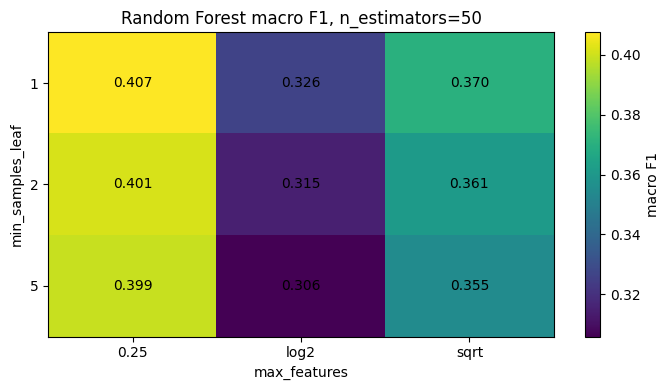

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))

im = ax.imshow(pivot_macro.values, aspect="auto")

ax.set_xticks(range(len(pivot_macro.columns)))
ax.set_xticklabels(pivot_macro.columns)

ax.set_yticks(range(len(pivot_macro.index)))
ax.set_yticklabels(pivot_macro.index)

ax.set_xlabel("max_features")
ax.set_ylabel("min_samples_leaf")
ax.set_title("Random Forest macro F1, n_estimators=50")

for i in range(len(pivot_macro.index)):
    for j in range(len(pivot_macro.columns)):
        value = pivot_macro.values[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="macro F1")
plt.tight_layout()
plt.savefig(FIG_PATH / "06_rf_n50_macro_heatmap")
plt.show()

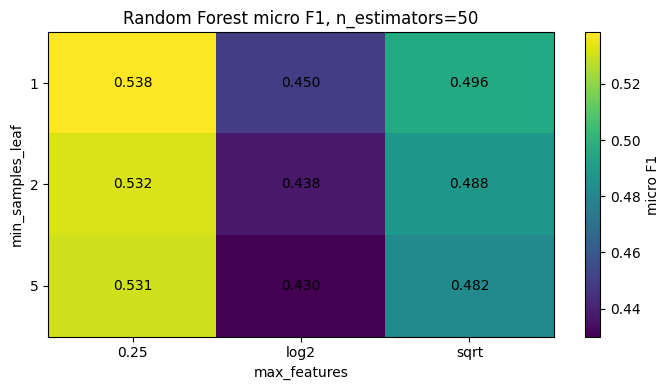

In [18]:
pivot_micro = rf_results_n50_df.pivot(
    index="min_samples_leaf",
    columns="max_features",
    values="micro_f1_mean",
)

fig, ax = plt.subplots(figsize=(7, 4))

im = ax.imshow(pivot_micro.values, aspect="auto")

ax.set_xticks(range(len(pivot_micro.columns)))
ax.set_xticklabels(pivot_micro.columns)

ax.set_yticks(range(len(pivot_micro.index)))
ax.set_yticklabels(pivot_micro.index)

ax.set_xlabel("max_features")
ax.set_ylabel("min_samples_leaf")
ax.set_title("Random Forest micro F1, n_estimators=50")

for i in range(len(pivot_micro.index)):
    for j in range(len(pivot_micro.columns)):
        value = pivot_micro.values[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="micro F1")
plt.tight_layout()
plt.savefig(FIG_PATH / "06_rf_n50_micro_heatmap")
plt.show()

## Final Evaluation using the test set:

In [19]:
def find_best_rf_params(rf_results, metric="macro_f1_mean"):
    """Return the best RF hyperparameter setting from the completed CV result dict."""
    rows = []

    for max_feat_key, leaf_results in rf_results.items():
        for min_leaf_key, entry in leaf_results.items():
            params = entry["params"].copy()
            rows.append({
                "n_estimators": params["n_estimators"],
                "max_features": params["max_features"],
                "min_samples_leaf": params["min_samples_leaf"],
                "macro_f1_mean": entry["macro_f1_mean"],
                "macro_f1_std": entry["macro_f1_std"],
                "micro_f1_mean": entry["micro_f1_mean"],
                "micro_f1_std": entry["micro_f1_std"],
            })

    df = pd.DataFrame(rows).sort_values(metric, ascending=False).reset_index(drop=True)
    best = df.iloc[0].to_dict()
    best_params = {
        "n_estimators": int(best["n_estimators"]),
        "max_features": best["max_features"],
        "min_samples_leaf": int(best["min_samples_leaf"]),
    }

    return best_params, df


best_rf_params, rf_selection_df = find_best_rf_params(rf_results_n50, metric="macro_f1_mean")

print("Best RF hyperparameters selected only from recording-grouped CV:")
print(best_rf_params)
print()
display(rf_selection_df.round(4))

Best RF hyperparameters selected only from recording-grouped CV:
{'n_estimators': 50, 'max_features': 0.25, 'min_samples_leaf': 1}



,n_estimators,max_features,min_samples_leaf,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,50,0.25,1,0.4074,0.0026,0.5384,0.0051
1,50,0.25,2,0.4013,0.0033,0.5323,0.0040
2,50,0.25,5,0.3989,0.0025,0.5306,0.0039
3,50,sqrt,1,0.3703,0.0037,0.4965,0.0063
4,50,sqrt,2,0.3613,0.0032,0.4880,0.0056
5,50,sqrt,5,0.3548,0.0050,0.4821,0.0083
6,50,log2,1,0.3263,0.0057,0.4497,0.0087
7,50,log2,2,0.3150,0.0073,0.4375,0.0094
8,50,log2,5,0.3060,0.0060,0.4300,0.0089


In [20]:
def fit_one_vs_rest_rf_final(train_files, label_dict, params):
    """
    Fit the final one-vs-rest Random Forest model on all development recordings.
    The imputer is fitted only on the development split.
    """
    X_train, y_train = build_fold_arrays(train_files, label_dict)
    y_train_h = (y_train >= 0.5).astype(np.int32)

    # RF does not need scaling, but we still replace inf values and impute missing values.
    steps = [
        ("inf_to_nan", FunctionTransformer(lambda X: np.where(np.isinf(X), np.nan, X),
                                           validate=False)),
        ("imputer", SimpleImputer(strategy="mean")),
    ]
    preprocessor = Pipeline(steps)
    X_train_c = preprocessor.fit_transform(X_train)

    models = []
    for c, class_name in enumerate(CLASS_NAMES):
        clf = RandomForestClassifier(
            n_estimators=params["n_estimators"],
            max_features=params["max_features"],
            min_samples_leaf=params["min_samples_leaf"],
            n_jobs=-1,
            random_state=42,
        )
        clf.fit(X_train_c, y_train_h[:, c])
        models.append(clf)
        print(f"Fitted class {c + 1:02d}/{N_CLASSES}: {class_name}")

    return {
        "preprocessor": preprocessor,
        "models": models,
        "params": params,
        "train_files": list(train_files),
    }


final_rf_model = fit_one_vs_rest_rf_final(
    train_files=rec_split["dev"],
    label_dict=hard_labels,
    params=best_rf_params,
)

with open("rf_final_recording_grouped_model.pkl", "wb") as f:
    pickle.dump(final_rf_model, f)

print("Saved final model to rf_final_recording_grouped_model.pkl")

Fitted class 01/15: bell_ringing
Fitted class 02/15: coffee_machine
Fitted class 03/15: cutlery_dishes
Fitted class 04/15: door_open_close
Fitted class 05/15: footsteps
Fitted class 06/15: keyboard_typing
Fitted class 07/15: keychain
Fitted class 08/15: light_switch
Fitted class 09/15: microwave
Fitted class 10/15: phone_ringing
Fitted class 11/15: running_water
Fitted class 12/15: toilet_flushing
Fitted class 13/15: vacuum_cleaner
Fitted class 14/15: wardrobe_drawer_open_close
Fitted class 15/15: window_open_close


The first attempt to pickle the model bundle failed (`Can't pickle local object ... <lambda>`), because the imputation pipeline contained a lambda.
The traceback was removed. The next cell replaces it by a named module-level function so that the bundle can be saved.
To load `rf_final_recording_grouped_model.pkl` later, define `inf_to_nan_func` (see the next cell) before calling `pickle.load`.


In [21]:
def inf_to_nan_func(X):
    return np.where(np.isinf(X), np.nan, X)

final_rf_model["preprocessor"].steps[0] = (
    "inf_to_nan",
    FunctionTransformer(inf_to_nan_func, validate=False),
)

with open("rf_final_recording_grouped_model.pkl", "wb") as f:
    pickle.dump(final_rf_model, f)

print("Saved final model to rf_final_recording_grouped_model.pkl")

Saved final model to rf_final_recording_grouped_model.pkl


In [22]:
def predict_one_vs_rest_model(model_bundle, filenames, label_dict, threshold=0.5):
    """Predict labels for a list of recordings using a fitted one-vs-rest model bundle."""
    X_test, y_test = build_fold_arrays(filenames, label_dict)
    y_test_h = (y_test >= 0.5).astype(np.int32)

    X_test_c = model_bundle["preprocessor"].transform(X_test)
    y_pred = np.zeros_like(y_test_h)

    for c, clf in enumerate(model_bundle["models"]):
        # Robust handling in case a binary classifier has only one observed class.
        if hasattr(clf, "predict_proba") and len(clf.classes_) == 2:
            pos_col = list(clf.classes_).index(1)
            y_pred[:, c] = (clf.predict_proba(X_test_c)[:, pos_col] >= threshold).astype(np.int32)
        else:
            y_pred[:, c] = clf.predict(X_test_c).astype(np.int32)

    return y_test_h, y_pred


y_test_rf, y_pred_rf = predict_one_vs_rest_model(
    model_bundle=final_rf_model,
    filenames=rec_split["test"],
    label_dict=hard_labels,
    threshold=0.5,
)

rf_final_test_per_class = per_class_f1(y_test_rf, y_pred_rf)

rf_final_test_result = {
    "model": "RandomForestClassifier one-vs-rest",
    "split": "recording_grouped_split",
    "train_split": "recording_grouped_split['dev']",
    "test_split": "recording_grouped_split['test']",
    "selection_method": "Best macro F1 from recording-grouped CV on development split",
    "params": best_rf_params,
    "threshold": 0.5,
    "macro_f1": macro_f1(y_test_rf, y_pred_rf),
    "micro_f1": micro_f1(y_test_rf, y_pred_rf),
    "per_class_f1": rf_final_test_per_class.to_dict(),
    "n_train_recordings": len(rec_split["dev"]),
    "n_test_recordings": len(rec_split["test"]),
    "n_test_segments": int(y_test_rf.shape[0]),
}

print("Final held-out RF performance on recording_grouped_split['test']:")
print(f"macro F1: {rf_final_test_result['macro_f1']:.4f}")
print(f"micro F1: {rf_final_test_result['micro_f1']:.4f}")
print()

display(rf_final_test_per_class.sort_values(ascending=False).round(4).to_frame("f1"))

with open("06_rf_final_test_results.json", "w", encoding="utf-8") as f:
    json.dump(make_json_safe(rf_final_test_result), f, indent=2)

print("Saved final test results to 06_rf_final_test_results.json")

Final held-out RF performance on recording_grouped_split['test']:
macro F1: 0.4050
micro F1: 0.5426



,f1
running_water,0.7901
microwave,0.6695
vacuum_cleaner,0.6572
keyboard_typing,0.6366
phone_ringing,0.5961
keychain,0.5470
cutlery_dishes,0.4626
bell_ringing,0.4351
coffee_machine,0.4332
toilet_flushing,0.4202


Saved final test results to 06_rf_final_test_results.json
